In [23]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [24]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


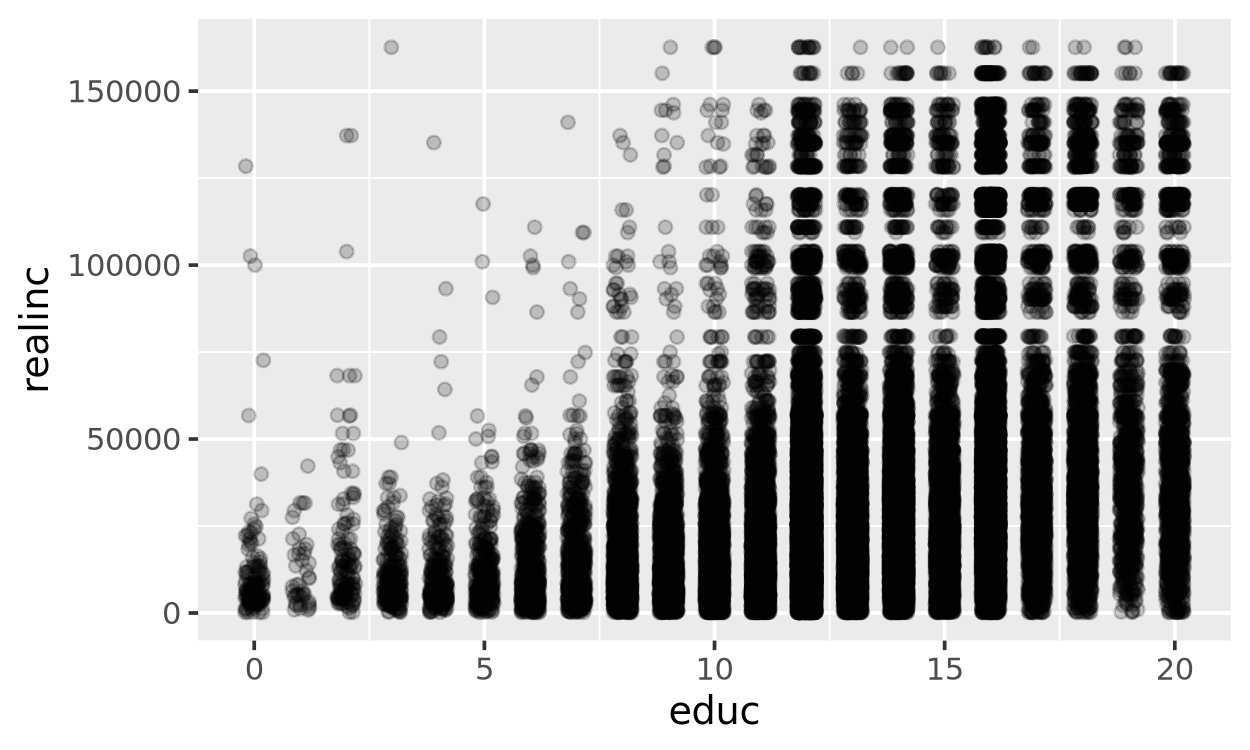

In [25]:
gss |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point(position = position_jitter(width = 0.2, height = 0.2), alpha = 0.2)

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


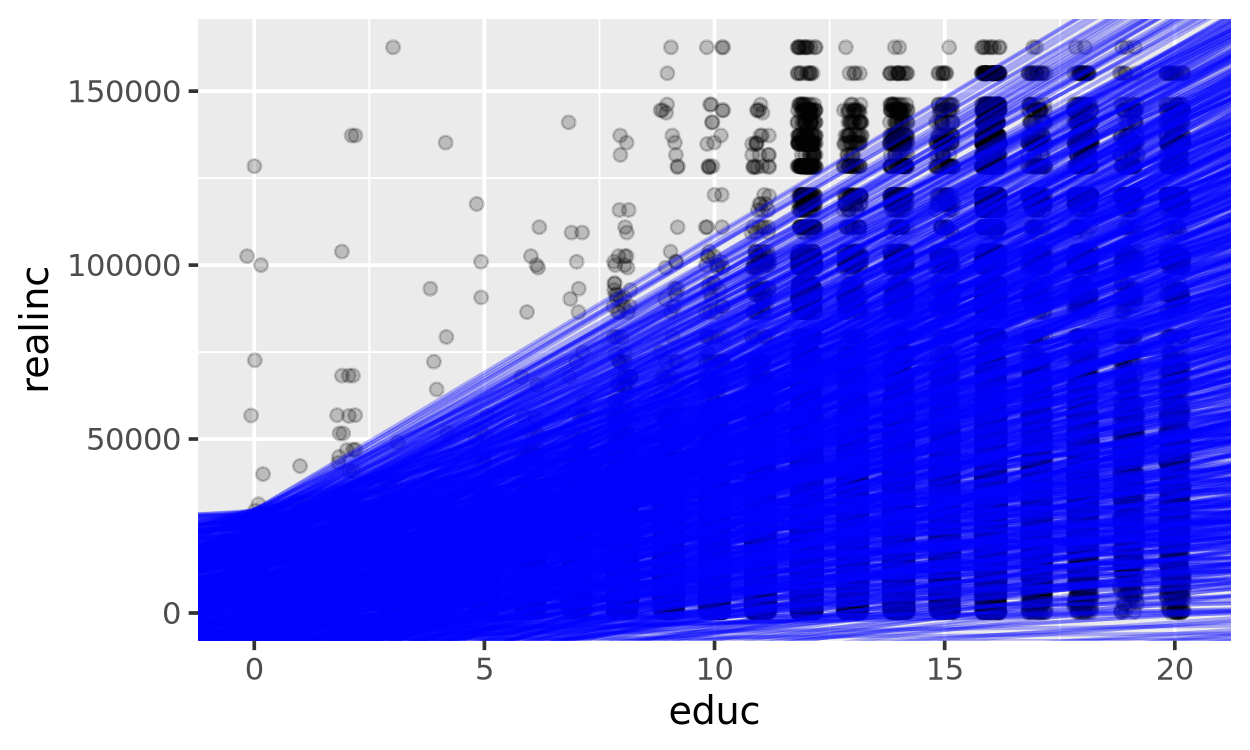

In [26]:
gss |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point(position = position_jitter(width = 0.2, height = 0.2), alpha = 0.2) +
    geom_abline(
        data = params,
        aes(intercept = intercept, slope = slope),
        color = 'blue',
        alpha = 0.3
    )

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


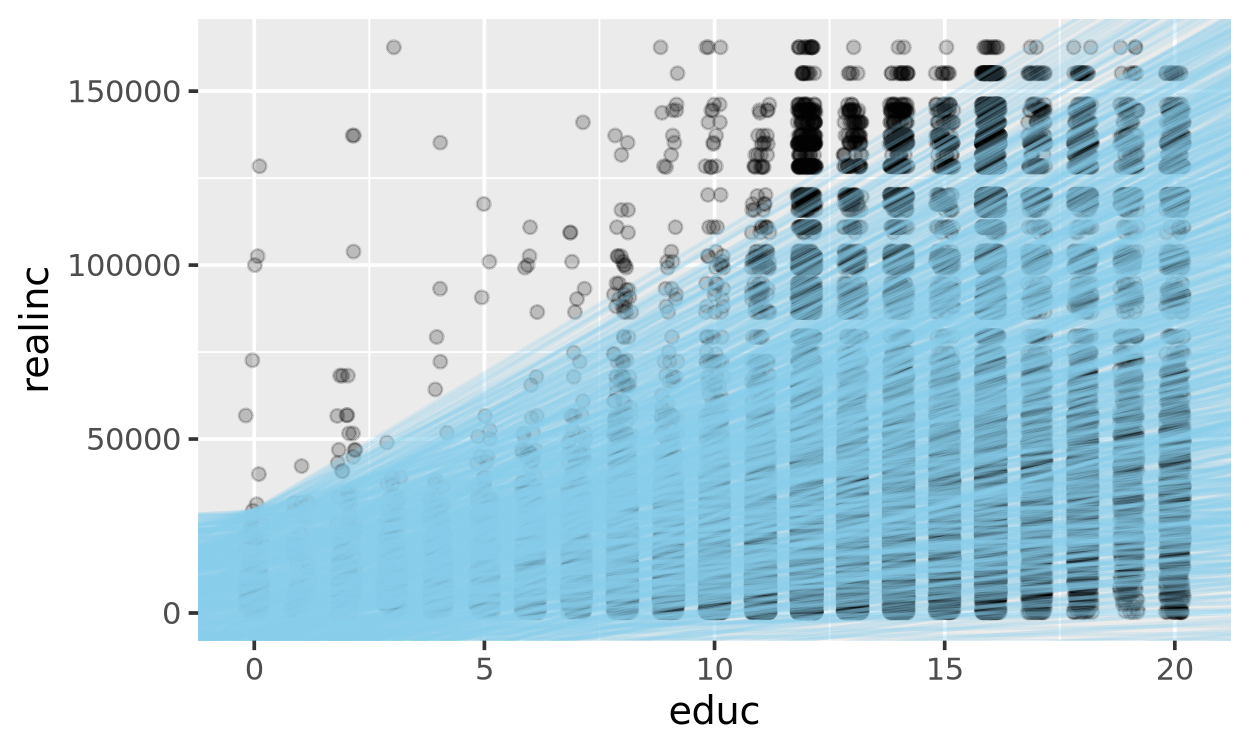

In [27]:
gss |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point(position = position_jitter(width = 0.2, height = 0.2), alpha = 0.2) +
    geom_abline(
        data = params,
        aes(intercept = intercept, slope = slope),
        color = 'sky blue',
        alpha = 0.2
    )

Steps for creating a model:
1. Pick the model form: a linear model

$$\text{realinc} = \beta_0 + \beta_1 \cdot \text{educ}$$

2. Design a way to evaluate different model parameters
3. Optimize our parameter values

In [28]:
income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

income_by_educ

   educ realinc
1   0   NA     
2   1   NA     
3   2   NA     
4   3   NA     
5   4   NA     
6   5   NA     
7   6   NA     
8   7   NA     
9   8   NA     
10  9   NA     
11 10   NA     
12 11   NA     
13 12   NA     
14 13   NA     
15 14   NA     
16 15   NA     
17 16   NA     
18 17   NA     
19 18   NA     
20 19   NA     
21 20   NA     
22 NA   NA     

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


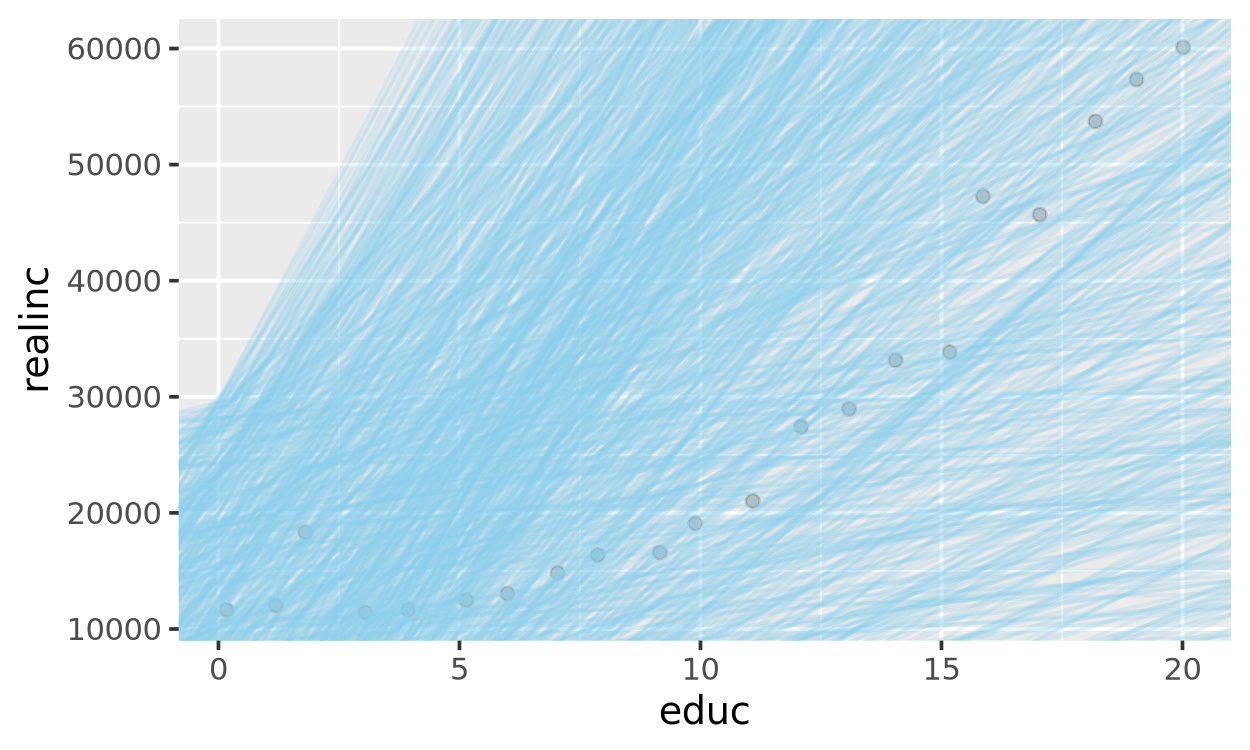

In [29]:
gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point(position = position_jitter(width = 0.2, height = 0.2), alpha = 0.2) +
    geom_abline(
        data = params,
        aes(intercept = intercept, slope = slope),
        color = 'sky blue',
        alpha = 0.2
        )

In [31]:
rmse_linear <- function(intercept, slope, data = gss) {
    predicted <- intercept + slope * data$educ
    sqrt(mean((data$realinc - predicted)^2, na.rm = TRUE))
}

In [32]:
params <- params |>
    rowwise() |>
    mutate(rmse = rmse_linear(intercept, slope)) |>
    ungroup()

params

     .rep intercept  slope     rmse    
1     1   -12745.349 2188.9819 33057.09
2     2    17298.308 4750.9355 55178.08
3     3    -5461.385 1281.4785 36073.79
4     4    22981.044 6827.4419 85677.12
5     5    26428.037 6781.9133 88332.82
6     6   -27266.610 3823.0945 29876.24
7     7     1686.329 6189.5370 58500.16
8     8    23545.143 2363.2006 36090.63
9     9     3086.101  525.0249 37455.21
10   10    -2603.116 3524.2650 30431.91
11   11    27410.001 3696.7909 51872.49
12   12    -2799.951 2727.4750 28431.03
13   13    10654.238 1481.1225 29163.50
14   14     4358.004 4055.9818 37885.88
15   15   -23824.519  153.5282 62232.39
16   16    23989.498 6189.4883 78572.02
17   17   -15234.736 4477.3206 30528.62
18   18   -27476.428 5131.7011 29674.85
19   19   -10324.757 3747.4569 29020.13
20   20    27270.219 2233.7905 37406.11
21   21    23372.359 3689.7326 48463.27
22   22    11568.204 6341.9067 69086.06
23   23     8430.409 4684.5246 47095.48
24   24    29656.187 3158.0719 47907.02
